# Projet Data Science — Diabetes 130-US Hospitals (1999–2008)
## Étape 1 — Exploration et visualisation du dataset

**Sommaire**
1. [Chargement et premier contact](#1.1-Chargement-et-premier-contact)
2. [La variable cible](#1.2-La-variable-cible)
3. [Les valeurs manquantes](#1.3-Les-valeurs-manquantes)
4. [Distributions des variables numériques et outliers](#1.4-Distributions-des-variables-numériques-et-outliers)
5. [Les variables catégorielles](#1.5-Les-variables-catégorielles)
6. [Relations entre les variables et avec la cible](#1.6-Relations-entre-les-variables-et-avec-la-cible)
7. [Les anomalies](#1.7-Les-anomalies)
8. [La synthèse finale](#1.8-La-synthèse-finale)

---
### 1.1 Chargement et premier contact

#### Premier chargement (brut)

In [1]:
import pandas as pd
df = pd.read_csv('diabetic_data.csv')

In [2]:
df.shape

(101766, 50)

In [3]:
pd.set_option('display.max_columns', None)   # afficher toutes les colonnes
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [5]:
df['weight'].value_counts()

weight
?            98569
[75-100)      1336
[50-75)        897
[100-125)      625
[125-150)      145
[25-50)         97
[0-25)          48
[150-175)       35
[175-200)       11
>200             3
Name: count, dtype: int64

#### Chargement corrigé (`?` → valeurs manquantes, `None` conservé)

In [1]:
import pandas as pd
df = pd.read_csv('diabetic_data.csv', na_values='?', keep_default_na=False, low_memory=False)

#### Vérification du chargement

In [8]:
print("Dimensions            :", df.shape)
print("'?' restants          :", (df == '?').sum().sum())
print("NaN dans race         :", df['race'].isna().sum())
print("NaN dans weight       :", df['weight'].isna().sum())
print("'None' dans A1Cresult :", (df['A1Cresult'] == 'None').sum())
print("'None' dans max_glu   :", (df['max_glu_serum'] == 'None').sum())

Dimensions            : (101766, 50)
'?' restants          : 0
NaN dans race         : 2273
NaN dans weight       : 98569
'None' dans A1Cresult : 84748
'None' dans max_glu   : 96420


#### Séjours ou patients ?

In [9]:
print(df['encounter_id'].nunique())
print(df['patient_nbr'].nunique())

101766
71518


In [10]:
sejours = df['patient_nbr'].value_counts()
print("Max de séjours pour un patient :", sejours.max())
print("Patients avec plus d'un séjour :", (sejours > 1).sum())
sejours.value_counts().sort_index().head(10)

Max de séjours pour un patient : 40
Patients avec plus d'un séjour : 16773


count
1     54745
2     10434
3      3328
4      1421
5       717
6       346
7       207
8       111
9        70
10       42
Name: count, dtype: int64

---
### 1.2 La variable cible

In [11]:
print(df['readmitted'].value_counts())
print(df['readmitted'].value_counts(normalize=True) * 100)

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64
readmitted
NO     53.911916
>30    34.928169
<30    11.159916
Name: proportion, dtype: float64


In [12]:
df['target'] = (df['readmitted'] == '<30').astype(int)
df['target'].value_counts(normalize=True) * 100

target
0    88.840084
1    11.159916
Name: proportion, dtype: float64

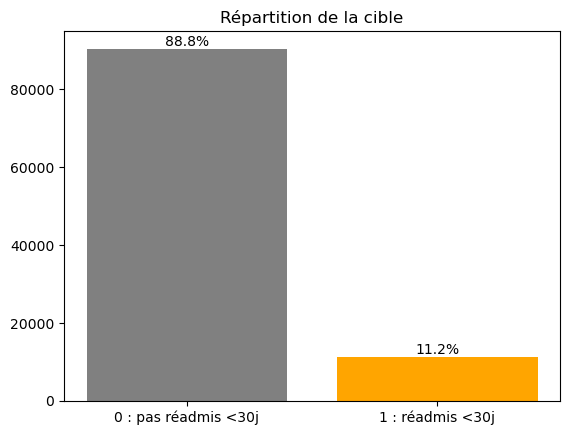

In [13]:
import matplotlib.pyplot as plt

vc = df['target'].value_counts().sort_index()
plt.bar(['0 : pas réadmis <30j', '1 : réadmis <30j'], vc.values, color=['gray', 'orange'])
for i, v in enumerate(vc.values):
    plt.text(i, v, f'{v/len(df):.1%}', ha='center', va='bottom')
plt.title('Répartition de la cible')
plt.show()

####  Conclusion — Analyse de la cible
- Nous voulons détecter les patients qui reviennent à l'hôpital **en moins de 30 jours**, car c'est le signe d'une mauvaise prise en charge. Donc `<30` = 1, et `>30` + `NO` = 0.
- La cible est **déséquilibrée** : 89 % de 0 et 11 % de 1.
- Un modèle qui répond toujours 0 aurait 89 % d'accuracy sans trouver aucun patient à risque. L'accuracy n'est donc **pas une bonne mesure** ici. Nous utiliserons plutôt le **recall** (combien de patients à risque sont réellement détectés).

---
### 1.3 Les valeurs manquantes

#### A. Les manquants visibles (`?` devenus NaN)

In [14]:
manquants = df.isna().mean() * 100
manquants = manquants[manquants > 0].sort_values(ascending=False)
manquants.round(2)

weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

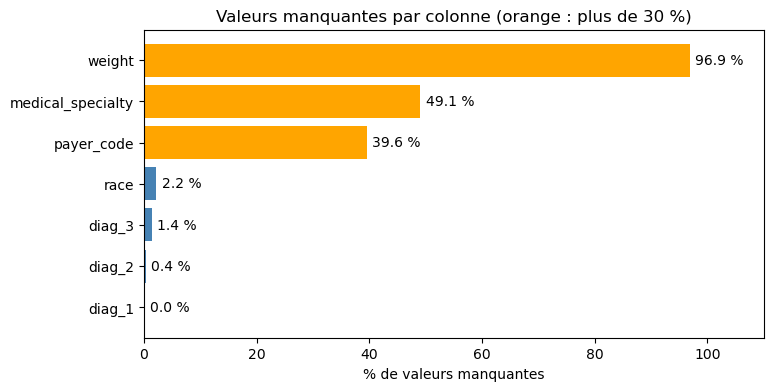

In [15]:
import matplotlib.pyplot as plt

couleurs = ['orange' if v > 30 else 'steelblue' for v in manquants.values]
plt.figure(figsize=(8, 4))
plt.barh(manquants.index, manquants.values, color=couleurs)
for i, v in enumerate(manquants.values):
    plt.text(v + 1, i, f'{v:.1f} %', va='center')
plt.xlabel('% de valeurs manquantes')
plt.title('Valeurs manquantes par colonne (orange : plus de 30 %)')
plt.xlim(0, 110)
plt.gca().invert_yaxis()
plt.show()

#### B. Les manquants déguisés en codes

In [16]:
codes_inconnus = {
    'admission_type_id':        [5, 6, 8],
    'discharge_disposition_id': [18, 25, 26],
    'admission_source_id':      [9, 15, 17, 20, 21],
}
for col, codes in codes_inconnus.items():
    pct = df[col].isin(codes).mean() * 100
    print(f"{col:26s} : {pct:.1f} % de codes 'inconnu'")

admission_type_id          : 10.2 % de codes 'inconnu'
discharge_disposition_id   : 4.6 % de codes 'inconnu'
admission_source_id        : 6.9 % de codes 'inconnu'


#### C. `gender` invalide

In [17]:
df['gender'].value_counts()

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

#### D. Le faux manquant : `None` dans les examens

In [18]:
print(df['A1Cresult'].value_counts(normalize=True) * 100)
print(df['max_glu_serum'].value_counts(normalize=True) * 100)

A1Cresult
None    83.277322
>8       8.073423
Norm     4.903406
>7       3.745848
Name: proportion, dtype: float64
max_glu_serum
None    94.746772
Norm     2.551933
>200     1.459230
>300     1.242065
Name: proportion, dtype: float64


> **Remarque :** Ce n'est pas un manquant : `None` veut dire que l'examen n'a pas été fait. Le médecin a décidé de ne pas le prescrire, et c'est une information.

---
### 1.4 Distributions des variables numériques et outliers

#### Lister les variables numériques

In [19]:
numeriques = ['time_in_hospital', 'num_lab_procedures', 'num_procedures',
              'num_medications', 'number_outpatient', 'number_emergency',
              'number_inpatient', 'number_diagnoses']

#### Statistiques descriptives

In [20]:
df[numeriques].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.34,1.71,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.42,1.93,1.0,6.0,8.0,9.0,16.0


**Exemple avec `number_emergency`**

Cette colonne compte combien de fois le patient est passé aux urgences dans l'année précédant son séjour.
- **Médiane = 0** : le patient du milieu n'est jamais passé aux urgences. Donc au moins la moitié des patients n'y est jamais allée.
- **Max = 76** : un patient y est passé 76 fois.

**Pourquoi c'est un signal ?**

Quand la médiane et le max sont proches, les valeurs sont regroupées et il n'y a pas de surprise. Quand le max est très loin de la médiane (0 contre 76), cela veut dire que quelques patients sont très différents de tous les autres. Ce sont les valeurs extrêmes, ou outliers.

#### Histogrammes

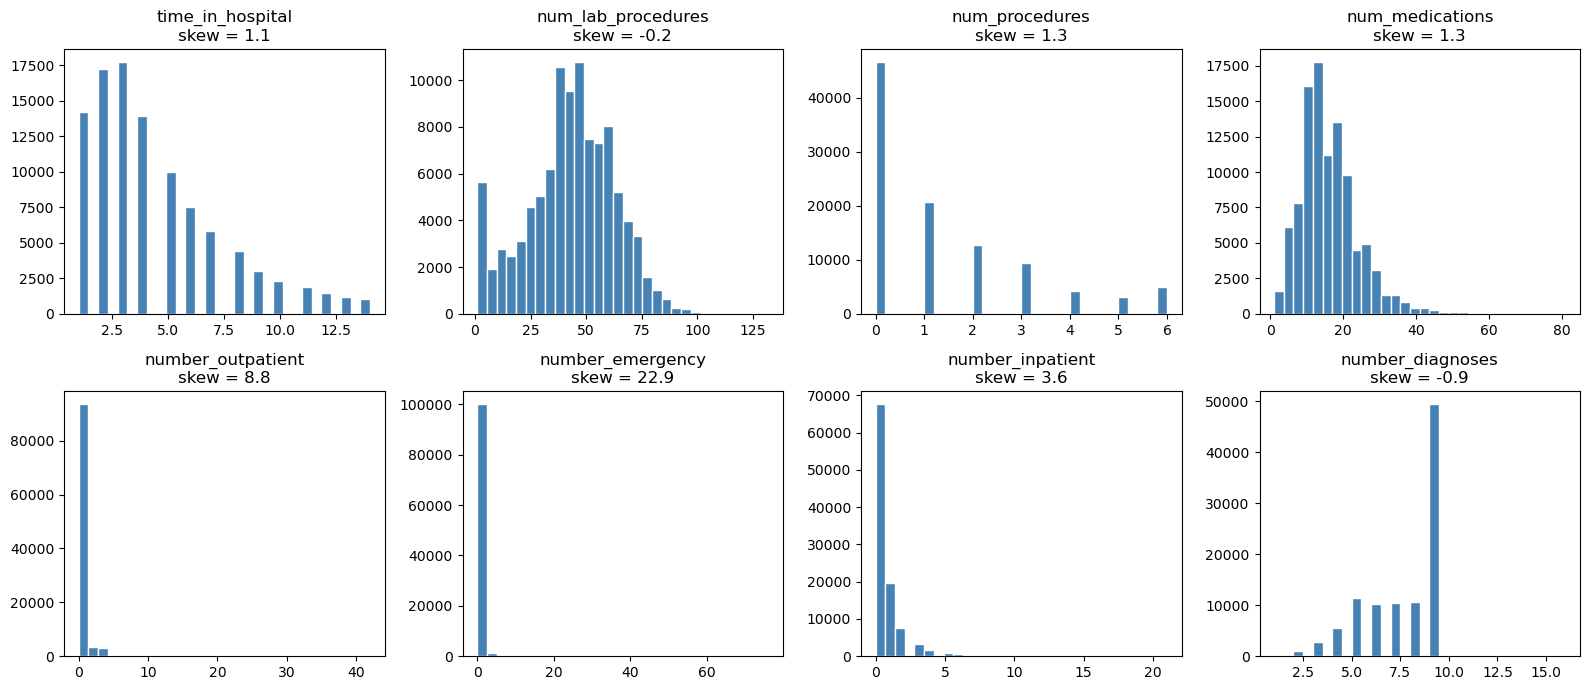

In [22]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), numeriques):
    ax.hist(df[col], bins=30, color='steelblue', edgecolor='white')
    ax.set_title(f"{col}\nskew = {df[col].skew():.1f}")
plt.tight_layout()
plt.show()

#### Lecture des histogrammes

**1. `time_in_hospital` — durée du séjour**
- *C'est quoi :* le nombre de jours entre l'entrée et la sortie de l'hôpital.
- *Ce que raconte l'histogramme :* la plupart des patients restent 2 à 4 jours (médiane : 4 jours). Plus le séjour est long, plus il est rare. Il n'y a rien au-delà de 14 jours, car l'étude n'a gardé que des séjours de 1 à 14 jours. Cette limite de 14 jours est un critère de sélection, pas une réalité médicale.

**2. `num_lab_procedures` — nombre d'analyses de laboratoire**
- *C'est quoi :* combien d'analyses ont été faites pendant le séjour : prises de sang, analyses d'urine, glycémie, etc. Chaque test compte pour 1.
- *Ce que raconte l'histogramme :* une cloche centrée autour de 44 analyses. C'est la variable la plus « normale » du dataset. On voit aussi un pic bizarre à 1 analyse (3 208 séjours), isolé à gauche. Ce sont des séjours presque sans analyse, ce qui est étonnant pour un patient hospitalisé. C'est une anomalie à signaler.

**3. `num_procedures` — nombre d'actes médicaux**
- *C'est quoi :* les actes autres que les analyses : radiographie, scanner, pose de cathéter, petite chirurgie, etc.
- *Ce que raconte l'histogramme :* 46 % des séjours n'ont aucun acte, et le maximum est de 6. La plupart des patients sont surveillés et traités, sans intervention.

**4. `num_medications` — nombre de médicaments différents**
- *C'est quoi :* combien de médicaments différents ont été donnés pendant le séjour, tous médicaments confondus et pas seulement ceux du diabète.
- *Ce que raconte l'histogramme :* la plupart des patients reçoivent 10 à 20 médicaments (médiane : 15), avec une queue vers la droite qui va jusqu'à 81. Ce sont des patients diabétiques, souvent âgés, avec plusieurs maladies à la fois, donc beaucoup de traitements.

**5. `number_outpatient` — consultations externes l'année d'avant**
- *C'est quoi :* combien de fois le patient est venu à l'hôpital sans y dormir (consultation, rendez-vous) pendant les 12 mois avant ce séjour.
- *Ce que raconte l'histogramme :* un mur à 0. 84 % des patients n'ont eu aucune consultation, et quelques-uns en ont eu jusqu'à 42.

**6. `number_emergency` — passages aux urgences l'année d'avant**
- *C'est quoi :* combien de fois le patient est passé aux urgences pendant les 12 mois précédents.
- *Ce que raconte l'histogramme :* le mur à 0 le plus extrême. 89 % des patients n'y sont jamais allés, mais un patient y est passé 76 fois, soit plus d'une fois par semaine. C'est la variable la plus asymétrique (skew = 22,9).

**7. `number_inpatient` — hospitalisations l'année d'avant**
- *C'est quoi :* combien de fois le patient a été hospitalisé (avec nuitées) pendant les 12 mois précédents.
- *Ce que raconte l'histogramme :* 67 % n'ont pas été hospitalisés, mais un tiers l'a été au moins une fois, et jusqu'à 21 fois. C'est la variable d'historique la moins écrasée à 0. Elle deviendra d'ailleurs le meilleur indicateur de réadmission, comme on le verra à l'étape 1.6.

**8. `number_diagnoses` — nombre de diagnostics enregistrés**
- *C'est quoi :* combien de maladies ou problèmes de santé ont été saisis dans le système pour ce séjour.
- *Ce que raconte l'histogramme :* les barres montent doucement jusqu'à 8, puis il y a un pic énorme à 9 (48,6 % des séjours), puis presque plus rien. Il est peu probable que la moitié des patients ait exactement 9 maladies. Le plus probable, c'est que le logiciel de l'hôpital limitait la saisie à 9 diagnostics pendant une partie de la période. C'est une hypothèse, à présenter comme telle.

#### Asymétrie (skewness) et pourcentage de zéros

**Calcul de skewness (l'asymétrie) :**
- si proche de 0 ⇒ symétrique
- si valeur grande et positive ⇒ il y a une longue queue à droite (le « toboggan » ou le « mur à 0 »).

In [23]:
stats = pd.DataFrame({
    'skewness': df[numeriques].skew().round(2),
    '% de zéros': ((df[numeriques] == 0).mean() * 100).round(1),
})
stats.sort_values('skewness', ascending=False)

,skewness,% de zéros
number_emergency,22.86,88.8
number_outpatient,8.83,83.6
number_inpatient,3.61,66.5
num_medications,1.33,0.0
num_procedures,1.32,45.8
time_in_hospital,1.13,0.0
num_lab_procedures,-0.24,0.0
number_diagnoses,-0.88,0.0


> Le skew seul ne dit pas pourquoi une variable est asymétrique. Le % de zéros donne l'explication : `number_emergency` est asymétrique parce que 89 % des valeurs sont à 0 et que quelques-unes sont très grandes.

#### Boxplots (outliers)

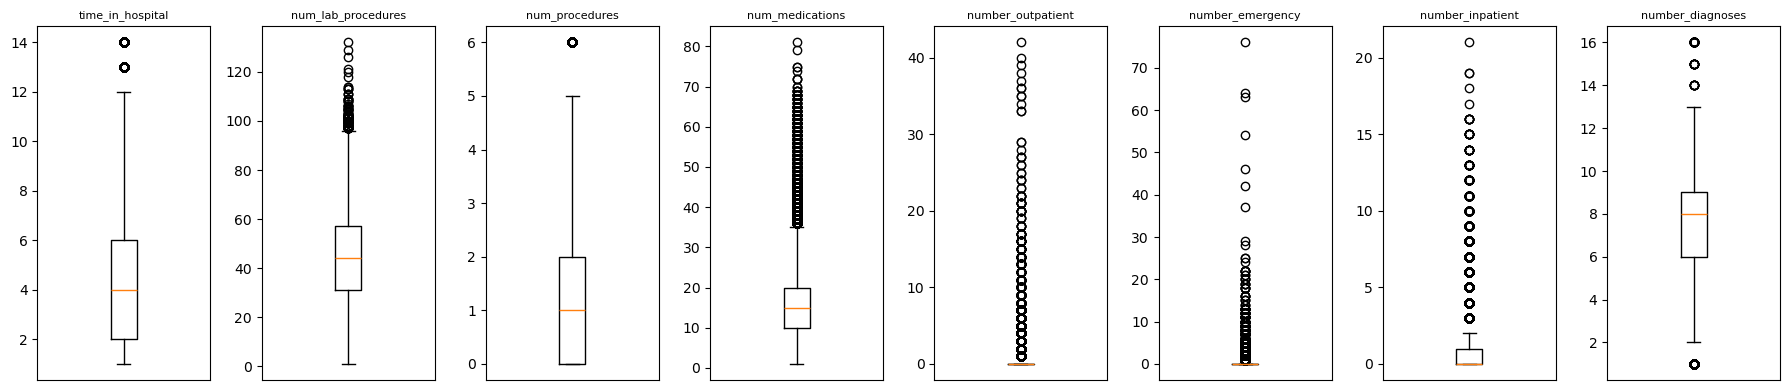

In [28]:
#Boxplots pour voir les outliers
fig, axes = plt.subplots(1, 8, figsize=(18, 4))
for ax, col in zip(axes, numeriques):
    ax.boxplot(df[col])
    ax.set_title(col, fontsize=8)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

**Cas 1 : peu d'outliers, proches** (`time_in_hospital`, `num_procedures`, `number_diagnoses`)
Quelques points juste au-dessus ou en dessous de la moustache. Ce sont des valeurs un peu rares, mais pas choquantes.

**Cas 2 : une « colonne » de points au-dessus** (`num_lab_procedures`, `num_medications`)
La boîte est normale, mais il y a beaucoup de points empilés au-dessus. Quelques patients ont énormément d'analyses ou de médicaments (jusqu'à 81 médicaments). Ce sont des patients lourds, qui existent réellement.

**Cas 3 : la boîte est écrasée à 0** (`number_outpatient`, `number_emergency`, `number_inpatient`)
On ne voit presque pas de boîte : juste un trait à 0, avec des points qui montent très haut. Q1 = 0 et Q3 = 0, donc IQR = 0 et la moustache s'arrête à 0. Du coup, tout patient avec au moins 1 visite est classé comme outlier. C'est le piège : la règle marque comme « anormaux » des patients parfaitement réels.

---

**L'exemple : 10 patients**

On regarde combien de fois chacun est passé aux urgences l'année dernière :

`0   0   0   0   0   0   0   0   2   5`

8 patients n'y sont jamais allés, un y est allé 2 fois, un autre 5 fois.

**Ce que fait la règle de l'IQR**
- Q1 (le quart des valeurs) = 0
- Q3 (les trois quarts des valeurs) = 0
- IQR = Q3 − Q1 = 0 − 0 = 0
- Limite haute = Q3 + 1,5 × 0 = 0

La règle dit donc : « tout ce qui est au-dessus de 0 est un outlier ». Résultat : le patient passé 2 fois aux urgences est classé comme « aberrant ».

**Pourquoi ça n'a pas de sens**

Aller 2 fois aux urgences en un an, c'est normal et ça arrive réellement. Ce n'est ni une erreur de saisie ni une valeur impossible.

La règle se trompe ici parce que presque tout le monde a 0. Il y a tellement de zéros que tout ce qui n'est pas zéro paraît « bizarre ».

#### Pourcentage d'outliers (règle IQR)

In [29]:
def pct_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100

pd.Series({col: pct_outliers(df[col]) for col in numeriques}).round(1)

time_in_hospital       2.2
num_lab_procedures     0.1
num_procedures         4.9
num_medications        2.5
number_outpatient     16.4
number_emergency      11.2
number_inpatient       6.9
number_diagnoses       0.3
dtype: float64

####  Conclusion — Distributions des variables numériques
- `num_lab_procedures` a une distribution proche de la symétrie (skew ≈ -0,2).
- `time_in_hospital`, `num_medications` et `num_procedures` sont modérément asymétriques à droite (skew entre 1,1 et 1,3) : la plupart des séjours sont courts ou avec peu de traitements, quelques-uns beaucoup plus.
- `number_emergency`, `number_outpatient` et `number_inpatient` sont **très asymétriques** (skew jusqu'à 22,9) et majoritairement nulles (66 à 89 % de zéros) : la plupart des patients n'ont aucune visite antérieure, quelques-uns en ont beaucoup.
- `number_diagnoses` présente un pic très marqué à 9, qui correspond probablement à une limite du système de saisie (hypothèse).

####  Conclusion — Outliers
La règle IQR détecte beaucoup d'outliers dans les variables de visites antérieures (jusqu'à 16 %). Mais comme la majorité des valeurs vaut 0, cette règle classe toute valeur non nulle comme aberrante. Ces valeurs sont **plausibles médicalement** (un patient peut réellement avoir plusieurs passages aux urgences) et sont probablement liées au risque de réadmission. Nous ne les supprimerons donc pas : elles seront transformées à l'étape 2 pour réduire leur asymétrie.

---
### 1.5 Les variables catégorielles

**Objectif :** Voir comment se répartissent les variables qui ne sont pas des nombres, mais des catégories (âge par tranches, sexe, type d'admission, médicaments…), et repérer leurs problèmes.

**Qu'est-ce qu'une variable catégorielle ?** Une variable dont les valeurs sont des étiquettes, pas des quantités. Par exemple : `gender` = Female / Male. On ne peut pas faire « Female + Male ». On peut seulement compter combien il y a de chaque.

Pour ces variables, l'outil principal est donc `value_counts()`, et le graphique adapté est le diagramme en barres.

#### A. Variables démographiques : qui sont les patients ?

In [31]:
# Répartition des patients par âge, origine et sexe (en %)
for col in ['age', 'race', 'gender']:
    print(col)
    print((df[col].value_counts(normalize=True, dropna=False) * 100).round(1))
    print()

age
age
[70-80)     25.6
[60-70)     22.1
[50-60)     17.0
[80-90)     16.9
[40-50)      9.5
[30-40)      3.7
[90-100)     2.7
[20-30)      1.6
[10-20)      0.7
[0-10)       0.2
Name: proportion, dtype: float64

race
race
Caucasian          74.8
AfricanAmerican    18.9
NaN                 2.2
Hispanic            2.0
Other               1.5
Asian               0.6
Name: proportion, dtype: float64

gender
gender
Female             53.8
Male               46.2
Unknown/Invalid     0.0
Name: proportion, dtype: float64



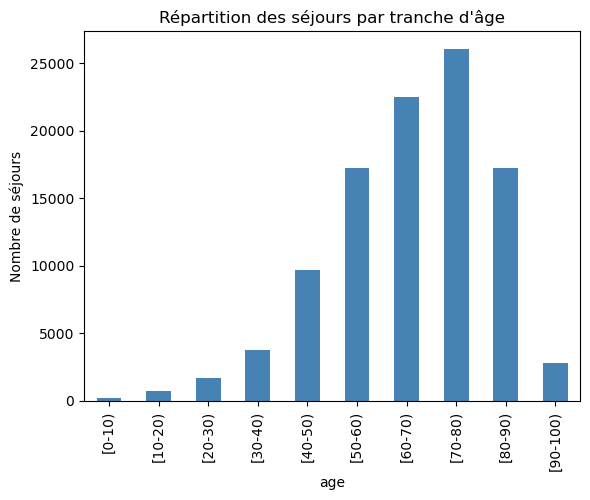

In [32]:
# Nombre de séjours par tranche d'âge (triées dans l'ordre)
ordre = sorted(df['age'].unique())
df['age'].value_counts().reindex(ordre).plot(kind='bar', color='steelblue')
plt.title("Répartition des séjours par tranche d'âge")
plt.ylabel('Nombre de séjours')
plt.show()

#### B. Variables administratives : comment arrivent et repartent les patients ?

In [33]:
# Dictionnaires de traduction des codes (tirés de IDS_mapping.csv)
admission_type = {1: 'Emergency', 2: 'Urgent', 3: 'Elective', 4: 'Newborn',
                  5: 'Not Available', 6: 'NULL', 7: 'Trauma Center', 8: 'Not Mapped'}

df['admission_type_label'] = df['admission_type_id'].map(admission_type)
(df['admission_type_label'].value_counts(normalize=True) * 100).round(1)

admission_type_label
Emergency        53.1
Elective         18.5
Urgent           18.2
NULL              5.2
Not Available     4.7
Not Mapped        0.3
Trauma Center     0.0
Newborn           0.0
Name: proportion, dtype: float64

In [34]:
# Les 5 codes de sortie et de source d'admission les plus fréquents
print((df['discharge_disposition_id'].value_counts(normalize=True) * 100).round(1).head(5))
print((df['admission_source_id'].value_counts(normalize=True) * 100).round(1).head(5))

discharge_disposition_id
1     59.2
3     13.7
6     12.7
18     3.6
2      2.1
Name: proportion, dtype: float64
admission_source_id
7     56.5
1     29.1
17     6.7
4      3.1
6      2.2
Name: proportion, dtype: float64


Le résultat affiche des codes. Il faut les traduire avec `IDS_mapping.csv` :

**Sortie (`discharge_disposition_id`)**

| Code | Signification | % |
|---|---|---|
| 1 | Rentré à domicile | 59,2 |
| 3 | Transféré en maison de soins (SNF) | 13,7 |
| 6 | Rentré à domicile avec soins à domicile | 12,7 |
| 18 | NULL (inconnu) | 3,6 |

**Source (`admission_source_id`)**

| Code | Signification | % |
|---|---|---|
| 7 | Arrivé par les urgences | 56,5 |
| 1 | Envoyé par un médecin | 29,1 |
| 17 | NULL (inconnu) | 6,7 |

#### C. Variables médicales : de quoi souffrent-ils ?

In [35]:
# Nombre de valeurs différentes pour chaque variable médicale
df[['medical_specialty', 'diag_1', 'diag_2', 'diag_3']].nunique()

medical_specialty     72
diag_1               716
diag_2               748
diag_3               789
dtype: int64

In [36]:
# Spécialité du médecin admettant (NaN = non renseignée)
df['medical_specialty'].value_counts(dropna=False).head(10)

medical_specialty
NaN                           49949
InternalMedicine              14635
Emergency/Trauma               7565
Family/GeneralPractice         7440
Cardiology                     5352
Surgery-General                3099
Nephrology                     1613
Orthopedics                    1400
Orthopedics-Reconstructive     1233
Radiologist                    1140
Name: count, dtype: int64

In [37]:
# Codes ICD-9 du diagnostic principal
df['diag_1'].value_counts().head(10)

diag_1
428    6862
414    6581
786    4016
410    3614
486    3508
427    2766
491    2275
715    2151
682    2042
434    2028
Name: count, dtype: int64

- Ces codes suivent la classification internationale des maladies (ICD-9). Par exemple, **428** = insuffisance cardiaque, **414** = maladie coronarienne, **786** = symptômes respiratoires ou thoraciques, **250.xx** = diabète.
- Le diagnostic principal le plus fréquent est cardiaque, et pas le diabète. Les patients sont diabétiques, mais ils viennent souvent pour autre chose. Ça confirme la problématique : le diabète est géré « au passage ».

#### D. Médicaments et examens

In [38]:
# Liste des 23 colonnes de médicaments (de metformin à metformin-pioglitazone)
meds = df.loc[:, 'metformin':'metformin-pioglitazone'].columns

# % de séjours où chaque médicament est prescrit (valeur différente de 'No')
usage = ((df[meds] != 'No').mean() * 100).sort_values(ascending=False).round(2)
usage

insulin                     53.44
metformin                   19.64
glipizide                   12.47
glyburide                   10.47
pioglitazone                 7.20
rosiglitazone                6.25
glimepiride                  5.10
repaglinide                  1.51
glyburide-metformin          0.69
nateglinide                  0.69
acarbose                     0.30
chlorpropamide               0.08
tolazamide                   0.04
miglitol                     0.04
tolbutamide                  0.02
glipizide-metformin          0.01
troglitazone                 0.00
metformin-rosiglitazone      0.00
acetohexamide                0.00
glimepiride-pioglitazone     0.00
metformin-pioglitazone       0.00
examide                      0.00
citoglipton                  0.00
dtype: float64

In [39]:
# Médicaments qui n'ont qu'une seule valeur dans tout le dataset
[m for m in meds if df[m].nunique() == 1]

['examide', 'citoglipton']

In [40]:
for col in ['insulin', 'change', 'diabetesMed']:
    print(col, (df[col].value_counts(normalize=True) * 100).round(1).to_dict())

insulin {'No': 46.6, 'Steady': 30.3, 'Down': 12.0, 'Up': 11.1}
change {'No': 53.8, 'Ch': 46.2}
diabetesMed {'Yes': 77.0, 'No': 23.0}


####  Conclusion — Variables catégorielles

**Profil des patients.** La population est âgée (majorité entre 50 et 90 ans, pic à 70–80 ans), majoritairement Caucasian (74,8 %) et AfricanAmerican (18,9 %), avec une répartition hommes/femmes équilibrée. `race` contient 2,2 % de valeurs manquantes et `gender` 3 valeurs invalides.

**Parcours hospitalier.** Plus de la moitié des admissions se font en urgence (53 %) et par les urgences (56 %). 59 % des patients rentrent à domicile, les autres sont transférés ou suivis à domicile. Ces trois variables sont des codes avec de nombreuses modalités rares et 5 à 10 % de codes « inconnus » : un regroupement sera nécessaire.

**Variables médicales.** `medical_specialty` (72 modalités, 49 % manquants) et surtout `diag_1/2/3` (plus de 700 codes chacun) ont une cardinalité trop élevée pour être utilisées directement : elles devront être regroupées (familles de diagnostics ICD-9, spécialités rares). Le diagnostic principal le plus fréquent est cardiaque (code 428), et non le diabète : les patients sont diabétiques mais hospitalisés pour une autre raison.

**Médicaments.** L'insuline est prescrite dans 53 % des séjours. 12 médicaments sur 23 sont quasi jamais prescrits (< 0,1 %) et 2 sont constants (`examide`, `citoglipton`) : ils n'apportent aucune information et seront supprimés.

---
### 1.6 Relations entre les variables et avec la cible

C'est l'étape la plus intéressante : on cherche ce qui est lié à la réadmission. Elle a deux parties :
- **A.** Les variables numériques sont-elles liées entre elles ?
- **B.** Quelles variables sont liées à la cible (`target`) ?

#### A. Relations entre les variables numériques

**L'idée :** si deux variables disent presque la même chose (par exemple, plus le séjour est long, plus il y a de médicaments), elles sont corrélées. Si la corrélation est très forte (au-dessus de 0,8), une des deux est inutile.

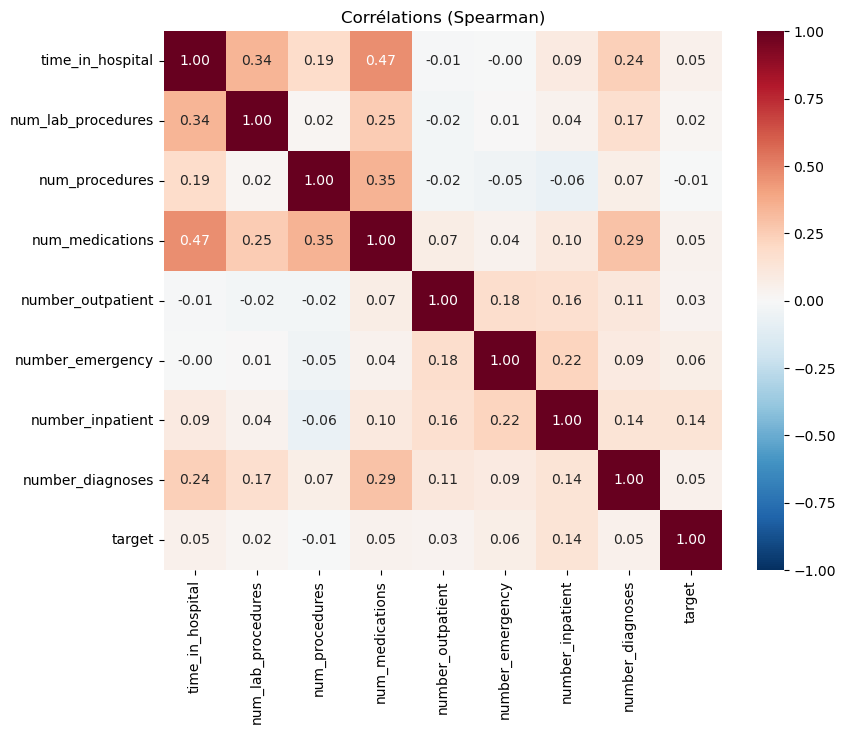

In [42]:
import seaborn as sns

# Corrélation de Spearman entre les variables numériques et la cible
corr = df[numeriques + ['target']].corr(method='spearman')

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Corrélations (Spearman)')
plt.show()

**Lecture de la carte :**
- **+1** (rouge foncé) : quand l'une monte, l'autre monte ;
- **0** (blanc) : aucun lien ;
- **-1** (bleu foncé) : quand l'une monte, l'autre descend.

- La plus forte corrélation est entre `time_in_hospital` et `num_medications` (0,47) : un séjour long demande plus de médicaments. C'est logique, mais c'est modéré, donc les deux variables restent utiles.
- Aucune paire au-dessus de 0,8, donc aucune variable n'est redondante.
- La ligne `target` : toutes les corrélations sont faibles (0,14 au maximum, pour `number_inpatient`). Aucune variable seule ne prédit bien la réadmission.

#### B. Relations avec la cible

##### Taux global de réadmission (référence)

In [43]:
taux_global = df['target'].mean() * 100
print(f"Taux global de réadmission <30j : {taux_global:.1f} %")

Taux global de réadmission <30j : 11.2 %


**À quoi sert ce chiffre ?** Il sert de ligne de référence pour la suite.

Un exemple de la vie courante : dans une ville, 11 personnes sur 100 attrapent la grippe cet hiver.
- Dans le quartier A, 40 sur 100 l'attrapent. C'est beaucoup plus que 11, donc ce quartier est dangereux.
- Dans le quartier B, 5 sur 100 l'attrapent. C'est moins que 11, donc ce quartier est plutôt protégé.

Sans le chiffre de la ville (11), on ne pourrait pas dire si 40 est « beaucoup » ou « normal ».

C'est exactement pareil ici :
- la « ville », c'est tous les patients : 11,2 % réadmis ;
- les « quartiers », ce sont des groupes de patients : ceux qui rentrent à domicile, ceux qui ont déjà été hospitalisés, etc.

##### Taux de réadmission selon les hospitalisations antérieures

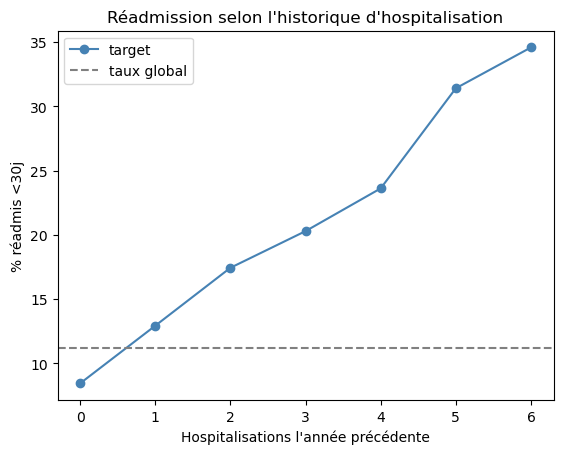

In [44]:
# Taux de réadmission selon le nombre d'hospitalisations l'année d'avant
taux = df.groupby('number_inpatient')['target'].mean() * 100
taux = taux[taux.index <= 6]          # au-delà de 6, trop peu de patients

taux.plot(marker='o', color='steelblue')
plt.axhline(taux_global, color='gray', linestyle='--', label='taux global')
plt.xlabel("Hospitalisations l'année précédente")
plt.ylabel('% réadmis <30j')
plt.title("Réadmission selon l'historique d'hospitalisation")
plt.legend()
plt.show()

Par exemple, la 1re ligne se lit : parmi les 67 630 séjours de patients jamais hospitalisés avant, 5 706 ont été suivis d'une réadmission, soit 5 706 ÷ 67 630 = 8,4 %.

Le taux augmente à chaque ligne. Plus un patient a été hospitalisé l'année d'avant, plus il revient souvent. La courbe du graphique ne fait que dessiner cette colonne.

##### Taux de réadmission selon les passages aux urgences

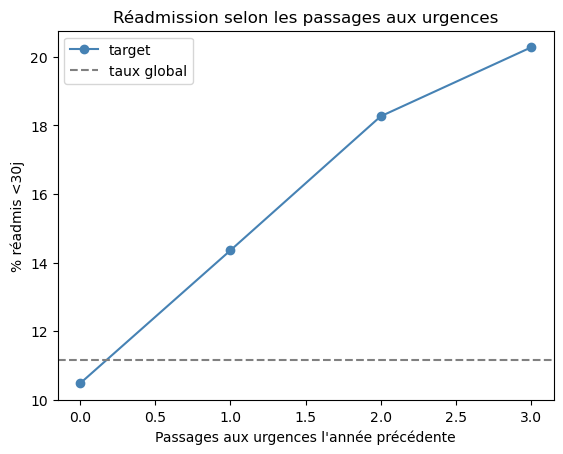

In [47]:
# Taux de réadmission selon le nombre de passages aux urgences l'année d'avant
taux = df.groupby('number_emergency')['target'].mean() * 100
taux = taux[taux.index <= 3]          # au-delà de 3, trop peu de patients

taux.plot(marker='o', color='steelblue')
plt.axhline(taux_global, color='gray', linestyle='--', label='taux global')
plt.xlabel("Passages aux urgences l'année précédente")
plt.ylabel('% réadmis <30j')
plt.title("Réadmission selon les passages aux urgences")
plt.legend()
plt.show()

##### Taux de réadmission selon la destination de sortie

In [48]:
# Taux de réadmission par code de sortie (seulement les codes avec au moins 500 séjours)
g = df.groupby('discharge_disposition_id')['target'].agg(['mean', 'size'])
g = g[g['size'] >= 500].sort_values('mean', ascending=False)
g['mean'] = (g['mean'] * 100).round(1)
g

,mean,size
discharge_disposition_id,,
22,27.7,1993
5,20.9,1184
2,16.1,2128
3,14.7,13954
7,14.4,623
4,12.8,815
6,12.7,12902
18,12.4,3691
25,9.3,989


Les patients transférés reviennent 1,5 à 3 fois plus souvent que ceux qui rentrent chez eux. Ils sont plus fragiles.

##### Taux de réadmission selon l'âge et l'HbA1c

In [49]:
for col in ['age', 'A1Cresult']:
    print((df.groupby(col)['target'].mean() * 100).round(1))
    print()

age
[0-10)       1.9
[10-20)      5.8
[20-30)     14.2
[30-40)     11.2
[40-50)     10.6
[50-60)      9.7
[60-70)     11.1
[70-80)     11.8
[80-90)     12.1
[90-100)    11.1
Name: target, dtype: float64

A1Cresult
>7      10.0
>8       9.9
None    11.4
Norm     9.7
Name: target, dtype: float64



Cette cellule vérifie deux questions avec la même méthode que les cellules précédentes (le taux de réadmission par groupe) :
1. L'âge influence-t-il la réadmission ?
2. Faire (ou non) l'examen HbA1c influence-t-il la réadmission ?

**Pourquoi ces deux variables-là**
- **L'âge**, parce qu'on s'attend spontanément à ce que les personnes âgées reviennent plus souvent. Il faut vérifier si c'est vrai dans les données.
- **HbA1c**, parce que c'est la question centrale de l'étude d'origine. Le texte du dataset dit que beaucoup de patients diabétiques ne reçoivent pas un bon suivi de leur glycémie. L'HbA1c est justement l'examen qui mesure l'équilibre du diabète sur les 3 derniers mois. La question est donc : « les patients chez qui on n'a pas fait l'examen reviennent-ils plus souvent ? »

##### Comparaison des moyennes : réadmis vs non réadmis

In [50]:
# Moyenne de chaque variable numérique, selon que le patient est réadmis (1) ou non (0)
df.groupby('target')[numeriques].mean().T.round(2)

target,0,1
time_in_hospital,4.35,4.77
num_lab_procedures,42.95,44.23
num_procedures,1.35,1.28
num_medications,15.91,16.90
number_outpatient,0.36,0.44
number_emergency,0.18,0.36
number_inpatient,0.56,1.22
number_diagnoses,7.39,7.69


####  Conclusion — Relations entre variables

**Entre variables numériques.** Les corrélations (Spearman, choisi car robuste aux distributions asymétriques) restent modérées : la plus forte relie `time_in_hospital` et `num_medications` (0,47), ce qui est logique (un séjour plus long implique plus de traitements). Aucune paire ne dépasse 0,8 : il n'y a pas de variable redondante à supprimer.

**Avec la cible.** Aucune variable n'est fortement corrélée seule à la réadmission (max 0,14), ce qui laisse prévoir des performances de classification modestes. Plusieurs tendances nettes apparaissent cependant :
- **L'historique hospitalier est le facteur le plus lié à la réadmission** : le taux passe d'environ 8 % sans hospitalisation antérieure à près de 40 % après 6 hospitalisations. Même tendance pour les passages aux urgences.
- **La destination de sortie compte** : les patients transférés (rééducation, autre établissement, maison de soins) sont réadmis dans 15 à 28 % des cas, contre 9,3 % pour ceux qui rentrent à domicile.
- **L'âge a peu d'effet** au-delà de 30 ans.
- Les séjours **sans mesure d'HbA1c** ont un taux légèrement supérieur (11,4 % contre environ 10 %). C'est une association, pas une relation de cause à effet.

**Conclusion.** Ce n'est pas le séjour actuel mais **l'historique du patient** et **son état à la sortie** qui sont le plus liés au risque de réadmission.

---
### 1.7 Les anomalies

**Objectif** : rassembler en un seul endroit tout ce qui est anormal dans les données.

In [51]:
# Codes de sortie correspondant à un décès ou à des soins palliatifs (voir IDS_mapping.csv)
deces = [11, 19, 20, 21]
palliatif = [13, 14]
sortie = df['discharge_disposition_id']

print("Séjours terminés par un décès      :", sortie.isin(deces).sum())
print("   dont réadmis <30j               :", df.loc[sortie.isin(deces), 'target'].sum())
print("Séjours en soins palliatifs        :", sortie.isin(palliatif).sum())
print("gender = Unknown/Invalid           :", (df['gender'] == 'Unknown/Invalid').sum())
print("Lignes dupliquées                  :", df.duplicated().sum())
print("Patients présents plusieurs fois   :", (df['patient_nbr'].value_counts() > 1).sum())
print("number_diagnoses = 9               :", round((df['number_diagnoses'] == 9).mean() * 100, 1), "%")
print("num_lab_procedures = 1             :", (df['num_lab_procedures'] == 1).sum())

meds = df.loc[:, 'metformin':'metformin-pioglitazone'].columns
print("Médicaments constants              :", [m for m in meds if df[m].nunique() == 1])

Séjours terminés par un décès      : 1652
   dont réadmis <30j               : 0
Séjours en soins palliatifs        : 771
gender = Unknown/Invalid           : 3
Lignes dupliquées                  : 0
Patients présents plusieurs fois   : 16773
number_diagnoses = 9               : 48.6 %
num_lab_procedures = 1             : 3208
Médicaments constants              : ['examide', 'citoglipton']


####  Conclusion — Anomalies détectées
- **Séjours incompatibles avec la cible** : 1 652 séjours se terminent par un décès (aucun n'est réadmis, par définition) et 771 par des soins palliatifs. Ces patients ne peuvent pas être réadmis : ils faussent la cible et devront être retirés.
- **Valeurs invalides** : 3 séjours ont `gender = Unknown/Invalid`.
- **Patients répétés** : 16 773 patients apparaissent plusieurs fois (aucune ligne n'est un doublon exact, ce sont des séjours différents). Risque de fuite de données entre train et test.
- **Colonnes constantes** : `examide` et `citoglipton` ont la même valeur pour tous les séjours et n'apportent aucune information.
- **Valeurs suspectes** : 48,6 % des séjours ont exactement 9 diagnostics (probable limite du système de saisie), et 3 208 séjours n'ont qu'une seule analyse de laboratoire, ce qui est inhabituel pour une hospitalisation. Ces valeurs sont conservées mais signalées.

---
### 1.8 La synthèse finale

#### Caractéristiques principales
- 101 766 séjours (lignes) et 50 variables, pour 71 518 patients : une ligne représente un séjour, et 16 773 patients ont plusieurs séjours.
- Cible binaire (réadmission en moins de 30 jours) **fortement déséquilibrée** : 11,2 % de réadmis. L'accuracy ne sera pas une métrique adaptée.
- Population âgée (majorité entre 50 et 90 ans), admise majoritairement en urgence.

#### Tendances principales
- **L'historique hospitalier est le facteur le plus lié à la réadmission** : le taux passe de 8,4 % (aucune hospitalisation l'année précédente) à 34,6 % (6 hospitalisations), et de 10,5 % à 20,3 % selon les passages aux urgences (0 à 3).
- **La destination de sortie compte** : 9,3 % de réadmission pour un retour à domicile, contre 14,7 % à 27,7 % pour un transfert vers un autre établissement.
- **L'âge et la mesure de l'HbA1c ont peu d'effet**.
- Aucune variable n'est fortement corrélée seule à la cible (max 0,14) : la classification devra combiner plusieurs variables et restera probablement modeste.

#### Problèmes à traiter à l'étape 2

| # | Problème | Variables | Ampleur |
|---|---|---|---|
| 1 | Séjours incompatibles avec la cible | `discharge_disposition_id` | 1 652 décès + 771 soins palliatifs |
| 2 | Patients présents plusieurs fois | `patient_nbr` | 16 773 patients |
| 3 | Manquants massifs | `weight` | 96,9 % |
| 4 | Manquants importants | `medical_specialty`, `payer_code` | 49,1 % / 39,6 % |
| 5 | Manquants faibles | `race`, `diag_1/2/3` | 2,2 % / < 1,5 % |
| 6 | Manquants déguisés en codes | 3 colonnes `*_id` | 10,2 % / 4,6 % / 6,9 % |
| 7 | Valeurs invalides | `gender` | 3 lignes |
| 8 | `None` = examen non réalisé (à garder) | `A1Cresult`, `max_glu_serum` | 83,3 % / 94,7 % |
| 9 | Trop de modalités | `diag_1/2/3`, `medical_specialty` | 700+ codes / 72 |
| 10 | Médicaments inutiles | 12 quasi vides, 2 constants | < 0,1 % |
| 11 | Forte asymétrie, beaucoup de zéros | `number_emergency/outpatient/inpatient` | skew 22,9 / 8,8 / 3,6 |
| 12 | Codes stockés en nombres | 3 colonnes `*_id` | à traiter en catégoriel |
| 13 | Valeurs suspectes | `number_diagnoses` = 9, `num_lab_procedures` = 1 | 48,6 % / 3 208 séjours |